<a href="https://colab.research.google.com/github/sanjyotsawant/CDAC_Training/blob/main/K_Nearest_Neighbours_PartA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score

COST_PER_TEST = 500   # ASSUMPTION: Rs per HbA1c test (not given in the brief) - change it

In [ ]:
df = pd.read_csv('sanjeevani_diabetes_screening_raw.csv', dtype=str)
df.shape


(3038, 13)

In [ ]:
df.columns

Index(['Patient ID', 'Camp Location', 'Sex', 'Age', 'family_history',
       'height_cm', 'weight_kg', 'BMI', 'waist_cm', 'Daily Steps',
       'Blood Pressure', 'total_cholesterol', 'HbA1c Result '],
      dtype='object')

In [ ]:

df.Sex.unique()


array(['female', 'Male', 'MALE', 'Female', 'F', 'M', 'male', 'FEMALE'],
      dtype=object)

In [ ]:

df.family_history.unique()

array(['No', '0', 'Y', 'Yes', 'N', 'no', '1', 'yes'], dtype=object)

In [ ]:

df['HbA1c Result '].unique()

array(['No', 'Negative', '0', 'DIABETIC', 'normal', 'Positive', '1',
       'Yes'], dtype=object)

In [ ]:
#Q.2
df.columns = (df.columns.str.strip().str.lower()
              .str.replace(r'[^0-9a-z]+', '_', regex=True).str.strip('_'))
df.columns

Index(['patient_id', 'camp_location', 'sex', 'age', 'family_history',
       'height_cm', 'weight_kg', 'bmi', 'waist_cm', 'daily_steps',
       'blood_pressure', 'total_cholesterol', 'hba1c_result'],
      dtype='object')

In [ ]:
# Q3
yes_no = {'0':0,'n':0,'no':0,'negative':0,'normal':0,
          '1':1,'y':1,'yes':1,'positive':1,'diabetic':1}
for c in ['family_history','hba1c_result']:
    df[c] = df[c].str.strip().str.lower().map(yes_no)
print(df[['family_history','hba1c_result']].isna().sum())   # should be 0
print("share positive: {:.1%}".format(df['hba1c_result'].mean()))

family_history    0
hba1c_result      0
dtype: int64
share positive: 22.5%


In [ ]:
print("before:", len(df))
print("exact duplicates:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("after:", len(df))

before: 3038
exact duplicates: 38
after: 3000


In [ ]:
# Q4
bp = df['blood_pressure'].str.split('/', expand=True)
df['systolic']  = pd.to_numeric(bp[0], errors='coerce')
df['diastolic'] = pd.to_numeric(bp[1], errors='coerce')
df = df.drop(columns='blood_pressure')
df[['systolic','diastolic']].describe()

,systolic,diastolic
count,2975.000000,2975.000000
mean,121.908571,80.753950
std,14.182369,10.630966
min,90.000000,55.000000
25%,112.000000,74.000000
50%,122.000000,81.000000
75%,132.000000,88.000000
max,178.000000,120.000000


In [ ]:
num_cols = ['age','height_cm','weight_kg','bmi','waist_cm','daily_steps','total_cholesterol']
for c in num_cols:
    df[c] = pd.to_numeric(df[c].str.replace(',', '', regex=False).str.strip(), errors='coerce')
df.dtypes

,0
patient_id,object
camp_location,object
sex,object
age,int64
family_history,int64
height_cm,float64
weight_kg,float64
bmi,float64
waist_cm,float64
daily_steps,float64


In [ ]:
# Q5

in_m = df['height_cm'] < 3          # e.g. 1.65 means metres
print("heights in metres:", in_m.sum())
df.loc[in_m, 'height_cm'] = df.loc[in_m, 'height_cm'] * 100
df['height_cm'].describe()

heights in metres: 45


,height_cm
count,3000.000000
mean,161.499667
std,9.167007
min,135.000000
25%,155.000000
50%,161.000000
75%,168.000000
max,193.000000


In [ ]:
blank = df['bmi'].isna()
print("blank BMI:", blank.sum())
rows = df.index[blank][:3]
cols = ['patient_id','height_cm','weight_kg','bmi']
print("BEFORE"); print(df.loc[rows, cols])

blank BMI: 320
BEFORE
   patient_id  height_cm  weight_kg  bmi
56   SD-22241      177.0       69.9  NaN
63   SD-21552      156.0       44.3  NaN
73   SD-22406      166.0       67.3  NaN


In [ ]:
df.loc[blank, 'bmi'] = (df.loc[blank,'weight_kg'] / (df.loc[blank,'height_cm']/100)**2).round(1)
print("AFTER"); print(df.loc[rows, cols])
print("blank BMI left:", df['bmi'].isna().sum())

AFTER
   patient_id  height_cm  weight_kg   bmi
56   SD-22241      177.0       69.9  22.3
63   SD-21552      156.0       44.3  18.2
73   SD-22406      166.0       67.3  24.4
blank BMI left: 0


In [ ]:
# Q6

bad = (df['age'] < 18) | (df['age'] > 100)
print("impossible ages:", sorted(df.loc[bad,'age'].unique()), "->", bad.sum(), "rows")
df.loc[bad, 'age'] = np.nan
df.isna().sum()

impossible ages: [np.int64(0), np.int64(3), np.int64(140), np.int64(999)] -> 7 rows


,0
patient_id,0
camp_location,0
sex,0
age,7
family_history,0
height_cm,0
weight_kg,0
bmi,0
waist_cm,90
daily_steps,60


In [ ]:
# Q7

names = np.array(['P1','P2','P3','P4','P5','P6'])
P = np.array([[76,6050],[80,5980],[101,7400],[96,8000],[106,4500],[82,6100]], dtype=float)
lab = np.array([0,0,1,1,1,0])          # 1 = Positive
new = np.array([98.0, 6000.0])

# working for P1:  sqrt((98-76)^2 + (6000-6050)^2) = sqrt(484 + 2500)
# working for P3:  sqrt((98-101)^2 + (6000-7400)^2) = sqrt(9 + 1960000)
d = np.sqrt(((P - new)**2).sum(axis=1))
print(pd.Series(d.round(2), index=names))
nn = np.argsort(d)[:3]
print("3 nearest:", names[nn], "-> prediction:", 'Positive' if lab[nn].mean() > .5 else 'Negative')

P1      54.63
P2      26.91
P3    1400.00
P4    2000.00
P5    1500.02
P6     101.27
dtype: float64
3 nearest: ['P2' 'P1' 'P6'] -> prediction: Negative


In [ ]:
# Q8

lo, hi = np.array([60.0, 0.0]), np.array([140.0, 20000.0])
Ps, news = (P - lo)/(hi - lo), (new - lo)/(hi - lo)
ds = np.sqrt(((Ps - news)**2).sum(axis=1))
print(pd.Series(ds.round(4), index=names))
nn = np.argsort(ds)[:3]
print("3 nearest:", names[nn], "-> prediction:", 'Positive' if lab[nn].mean() > .5 else 'Negative')

P1    0.2750
P2    0.2250
P3    0.0794
P4    0.1031
P5    0.1250
P6    0.2001
dtype: float64
3 nearest: ['P3' 'P4' 'P5'] -> prediction: Positive


In [ ]:
# Q9

dm = np.abs(Ps - news).sum(axis=1)
print(pd.Series(dm.round(4), index=names))
nn = np.argsort(dm)[:3]
print("3 nearest:", names[nn], "-> prediction:", 'Positive' if lab[nn].mean() > .5 else 'Negative')

P1    0.2775
P2    0.2260
P3    0.1075
P4    0.1250
P5    0.1750
P6    0.2050
dtype: float64
3 nearest: ['P3' 'P4' 'P5'] -> prediction: Positive


In [ ]:
# Q10

from sklearn.model_selection import train_test_split
feats = ['age','bmi','waist_cm','daily_steps','systolic','diastolic','total_cholesterol']
cats  = ['sex','family_history']
X = df[feats + cats]
y = df['hba1c_result']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
print("train positive rate: {:.2%}".format(y_train.mean()))
print("test  positive rate: {:.2%}".format(y_test.mean()))
baseline = (y_test == 0).mean()
print("baseline accuracy (everyone negative): {:.3f}".format(baseline))

train positive rate: 22.62%
test  positive rate: 22.67%
baseline accuracy (everyone negative): 0.773


In [ ]:
# Q11

def report(model, Xt, yt, thr=0.5):
    p = model.predict_proba(Xt)[:, 1]
    pred = (p >= thr).astype(int)
    m = dict(accuracy=accuracy_score(yt, pred), precision=precision_score(yt, pred, zero_division=0),
             recall=recall_score(yt, pred), f1=f1_score(yt, pred, zero_division=0), roc_auc=roc_auc_score(yt, p))
    return m, confusion_matrix(yt, pred), p

raw_knn = Pipeline([('imp', SimpleImputer(strategy='median')),
                    ('knn', KNeighborsClassifier(n_neighbors=5))])
raw_knn.fit(X_train[feats], y_train)
m_raw, cm_raw, p_raw = report(raw_knn, X_test[feats], y_test)
print({k: round(v,3) for k,v in m_raw.items()})
print(cm_raw)
print("model accuracy {:.3f}  vs  baseline {:.3f}".format(m_raw['accuracy'], baseline))
print("Accuracy is no better than 'everyone negative', but recall is only {:.2f}: most diabetics are missed.".format(m_raw['recall']))

{'accuracy': 0.763, 'precision': 0.441, 'recall': 0.176, 'f1': 0.252, 'roc_auc': np.float64(0.656)}
[[542  38]
 [140  30]]
model accuracy 0.763  vs  baseline 0.773
Accuracy is no better than 'everyone negative', but recall is only 0.18: most diabetics are missed.


In [ ]:
# Q12

sc_knn = Pipeline([('imp', SimpleImputer(strategy='median')),
                   ('sc', StandardScaler()),
                   ('knn', KNeighborsClassifier(n_neighbors=5))])
sc_knn.fit(X_train[feats], y_train)
m_sc, cm_sc, p_sc = report(sc_knn, X_test[feats], y_test)
pd.DataFrame({'unscaled': m_raw, 'scaled': m_sc}).round(3).T

,accuracy,precision,recall,f1,roc_auc
unscaled,0.763,0.441,0.176,0.252,0.656
scaled,0.788,0.552,0.341,0.422,0.723


In [ ]:
# which feature dominates the distance in the unscaled model?
imp_tr = raw_knn['imp'].transform(X_train[feats])
imp_te = raw_knn['imp'].transform(X_test[feats])
_, idx = raw_knn['knn'].kneighbors(imp_te)
sq = ((imp_te[:, None, :] - imp_tr[idx])**2).mean(axis=(0, 1))
share = pd.Series(sq/sq.sum(), index=feats).sort_values(ascending=False)
print((share*100).round(1).astype(str) + ' %')
print()
print(pd.Series(imp_tr.std(axis=0), index=feats).round(1))

daily_steps          50.8 %
total_cholesterol    23.0 %
systolic              8.5 %
age                   7.4 %
diastolic             5.1 %
waist_cm              4.0 %
bmi                   1.1 %
dtype: object

age                    11.9
bmi                     4.2
waist_cm                8.0
daily_steps          3071.8
systolic               14.0
diastolic              10.6
total_cholesterol      36.6
dtype: float64


In [ ]:
# Q 13

pipe = Pipeline([('imp', SimpleImputer(strategy='median')),
                 ('sc',  StandardScaler()),
                 ('knn', KNeighborsClassifier(n_neighbors=5))])
pipe.fit(X_train[feats], y_train)     # imputer + scaler learn from X_train only
pipe.predict(X_test[feats])

array([1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0,

best k: 51  AUC: 0.7876


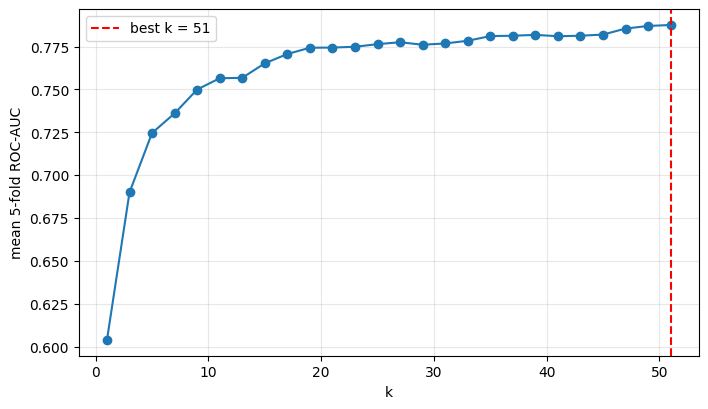

In [ ]:
# Q14

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
ks = list(range(1, 52, 2))
auc = []
for k in ks:
    p = Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler()),
                  ('knn', KNeighborsClassifier(n_neighbors=k))])
    auc.append(cross_val_score(p, X_train[feats], y_train, cv=skf, scoring='roc_auc').mean())
best_k = ks[int(np.argmax(auc))]
print("best k:", best_k, " AUC: {:.4f}".format(max(auc)))

plt.figure(figsize=(8,4.5))
plt.plot(ks, auc, marker='o')
plt.axvline(best_k, ls='--', color='red', label='best k = %d' % best_k)
plt.xlabel('k'); plt.ylabel('mean 5-fold ROC-AUC'); plt.legend(); plt.grid(alpha=.3)
plt.show()

In [ ]:
# Q15

allc = feats + cats
pre = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), feats),
    ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                      ('oh', OneHotEncoder(handle_unknown='ignore'))]), cats)])
full = Pipeline([('pre', pre), ('knn', KNeighborsClassifier())])
grid = {'knn__n_neighbors': list(range(3, 52, 2)),
        'knn__weights': ['uniform', 'distance'],
        'knn__p': [1, 2]}
gs = GridSearchCV(full, grid, scoring='roc_auc', cv=skf, n_jobs=-1)
gs.fit(X_train[allc], y_train)
print("best params:", gs.best_params_)
print("best CV ROC-AUC: {:.4f}".format(gs.best_score_))
tuned = gs.best_estimator_

best params: {'knn__n_neighbors': 51, 'knn__p': 2, 'knn__weights': 'distance'}
best CV ROC-AUC: 0.7977


In [ ]:
# Q16

m_tu, cm_tu, p_tu = report(tuned, X_test[allc], y_test)
print({k: round(v,3) for k,v in m_tu.items()})
print(cm_tu)
tn, fp, fn, tp = cm_tu.ravel()
print("TN = %d: healthy visitors we correctly did not send for a test" % tn)
print("FP = %d: healthy visitors we sent for a test they did not need" % fp)
print("FN = %d: diabetics we sent home without a test" % fn)
print("TP = %d: diabetics we correctly sent for a test" % tp)

{'accuracy': 0.805, 'precision': 0.8, 'recall': 0.188, 'f1': 0.305, 'roc_auc': np.float64(0.808)}
[[572   8]
 [138  32]]
TN = 572: healthy visitors we correctly did not send for a test
FP = 8: healthy visitors we sent for a test they did not need
FN = 138: diabetics we sent home without a test
TP = 32: diabetics we correctly sent for a test


Q 17

For including it:** camps may serve different communities (age, diet, income), so location can carry real signal about diabetes risk.
Against:** it describes the place, not the person. The model can't be used at a new camp, it may build in bias, and KNN might match people by camp instead of by health measurements.

In [ ]:
# Q18

print("recall at 0.5: {:.2f}".format(m_tu['recall']))

recall at 0.5: 0.19


In [ ]:
# Q19

total_pos = int(y_test.sum())
rows = []
for t in [0.1, 0.2, 0.3, 0.4, 0.5]:
    sel = p_tu >= t
    n, found = int(sel.sum()), int(y_test.values[sel].sum())
    rows.append({'threshold': t, 'tests_ordered': n, 'diabetics_found': found,
                 'diabetics_missed': total_pos - found,
                 'hit_rate': round(found/n, 3),
                 'cost_per_diabetic_Rs': round(n*COST_PER_TEST/found)})
pd.DataFrame(rows)

,threshold,tests_ordered,diabetics_found,diabetics_missed,hit_rate,cost_per_diabetic_Rs
0,0.1,531,161,9,0.303,1649
1,0.2,349,140,30,0.401,1246
2,0.3,204,105,65,0.515,971
3,0.4,107,64,106,0.598,836
4,0.5,40,32,138,0.800,625


In [ ]:
# Q20

BUDGET = 250
order = np.argsort(-p_tu, kind='stable')[:BUDGET]
found = int(y_test.values[order].sum())
print("top 250 finds", found, "of", total_pos, "diabetics")
print("random choice would find about", round(BUDGET*total_pos/len(y_test)))

top 250 finds 117 of 170 diabetics
random choice would find about 57


In [ ]:
# Q21

t = X_test
rule = (t['age'] >= 45) & (((t['sex']=='Male') & (t['waist_cm']>=90)) | ((t['sex']=='Female') & (t['waist_cm']>=80)))
rule_n, rule_found = int(rule.sum()), int(y_test[rule].sum())
print("rule: %d tests, %d diabetics, hit-rate %.1f%%" % (rule_n, rule_found, 100*rule_found/rule_n))
print("model: %d tests, %d diabetics, hit-rate %.1f%%" % (BUDGET, found, 100*found/BUDGET))
print("diabetics per Rs 1000:  rule %.2f   model %.2f" % (1000*rule_found/(rule_n*COST_PER_TEST), 1000*found/(BUDGET*COST_PER_TEST)))

rule: 250 tests, 92 diabetics, hit-rate 36.8%
model: 250 tests, 117 diabetics, hit-rate 46.8%
diabetics per Rs 1000:  rule 0.74   model 0.94


In [ ]:
# Q22

i = order[0]                                       # highest-ranked test visitor (change to pick another)
visitor = X_test.iloc[[i]]
Xt_train = tuned['pre'].transform(X_train[allc])
Xt_test  = tuned['pre'].transform(X_test[allc])
dist, nbr = tuned['knn'].kneighbors(Xt_test[[i]], n_neighbors=5)
_, nbr_all = tuned['knn'].kneighbors(Xt_test[[i]])  # all 51 neighbours the model really uses
show = ['age','sex','bmi','waist_cm','daily_steps','systolic','total_cholesterol','family_history']
print(visitor[show])
nb = X_train.iloc[nbr[0]][show].copy()
nb['hba1c_result'] = y_train.iloc[nbr[0]].values
nb['distance'] = dist[0].round(3)
print(nb)
share_pos = y_train.iloc[nbr_all[0]].mean()
print("\nShare of diabetics among all %d neighbours: %.0f%%" % (nbr_all.shape[1], 100*share_pos))

print('Volunteer: "We compared you with the %d past visitors whose age, waist, weight and activity are closest to yours,' % nbr_all.shape[1])
print('and %.0f%% of them had diabetes. A quick blood test is the best way to be sure; this is not a diagnosis."' % (100*share_pos))

       age     sex   bmi  waist_cm  daily_steps  systolic  total_cholesterol  \
1213  53.0  Female  35.2     108.0       5940.0     178.0              234.0   

      family_history  
1213               1  
       age     sex   bmi  waist_cm  daily_steps  systolic  total_cholesterol  \
1368  64.0  Female  30.4      98.0       4300.0     156.0              203.0   
2247  56.0  Female  34.0     101.0       4460.0     151.0              196.0   
1359  58.0  Female  29.3      95.0       6480.0     152.0              176.0   
1750  48.0    Male  32.8     113.0      11040.0     157.0              227.0   
442   45.0    Male  29.8     107.0       7450.0     149.0              206.0   

      family_history  hba1c_result  distance  
1368               1             1     2.839  
2247               1             0     3.323  
1359               1             1     3.344  
1750               0             1     3.493  
442                0             1     3.711  

Share of diabetics among all 

 Q 23

 The model doesn't look at weight alone. It compares your whole profile (age, waist, BMI, steps, blood pressure, cholesterol, family history) with past visitors and checks how many of the closest ones had diabetes. Your friend may weigh the same as you but be closer to diabetic visitors on the other measurements. We can only fund 250 tests and you were just outside the line. If you have symptoms, please see a doctor anyway.

In [ ]:
# Q24

def top_found(p):
    o = np.argsort(-p, kind='stable')[:BUDGET]
    return int(y_test.values[o].sum())

summary = pd.DataFrame({
    'accuracy':   [m_raw['accuracy'], m_sc['accuracy'], m_tu['accuracy']],
    'recall@0.5': [m_raw['recall'],   m_sc['recall'],   m_tu['recall']],
    'ROC-AUC':    [m_raw['roc_auc'],  m_sc['roc_auc'],  m_tu['roc_auc']],
    'found in top 250': [top_found(p_raw), top_found(p_sc), top_found(p_tu)]},
    index=['raw KNN', 'scaled KNN', 'tuned KNN']).round(3)
summary

,accuracy,recall@0.5,ROC-AUC,found in top 250
raw KNN,0.763,0.176,0.656,81
scaled KNN,0.788,0.341,0.723,99
tuned KNN,0.805,0.188,0.808,117


In [ ]:
# Q25

rule_at_250 = rule_found*BUDGET/rule_n
print(f'''Yes, camps should use the tuned, scaled KNN model, but as a ranking tool. In our test set it finds {found} of {total_pos} diabetics
in 250 tests, against about {round(BUDGET*total_pos/len(y_test))} for a random choice. On the day, volunteers enter age, waist, weight and height, steps,
blood pressure, cholesterol and family history, and the funded tests go to the highest-ranked visitors. Today's age + waist rule needs
{rule_n} tests to find {rule_found} diabetics (about {rule_at_250:.0f} per 250 tests), so the model finds roughly {found-rule_at_250:.0f} more per 250 tests.
One risk: the pilot data came only from six camps and from people who chose to attend, so it may under-represent other areas,
younger people and people who never come to camps. Re-check the results at a new camp before scaling up.''')

Yes, camps should use the tuned, scaled KNN model, but as a ranking tool. In our test set it finds 117 of 170 diabetics
in 250 tests, against about 57 for a random choice. On the day, volunteers enter age, waist, weight and height, steps,
blood pressure, cholesterol and family history, and the funded tests go to the highest-ranked visitors. Today's age + waist rule needs
250 tests to find 92 diabetics (about 92 per 250 tests), so the model finds roughly 25 more per 250 tests.
One risk: the pilot data came only from six camps and from people who chose to attend, so it may under-represent other areas,
younger people and people who never come to camps. Re-check the results at a new camp before scaling up.
